<a href="https://colab.research.google.com/github/germanricardovilla-collab/telecom-analysis/blob/main/S7_Version_Estudiante_Project_ConnectaTel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel.

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


---
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [ ]:
plans.head()

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [ ]:
users.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [ ]:
usage.head()

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [ ]:
# revisar el número de filas y columnas de cada dataset
print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)

plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [ ]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [ ]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [ ]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [ ]:
# cantidad de nulos para users
city_missing= users['city'].isna().sum()
churn_date_missing= users['churn_date'].isna().sum()

# Total de filas del dataset
total_filas = len(users)

# Porcentaje de nulos por columna
city_missing_pct = (city_missing/total_filas)*100
churn_date_missing_pct= (churn_date_missing/total_filas)*100

print(f'missing city: {city_missing} ({city_missing_pct:2f}%)')
print(f'missing  churn date: {churn_date_missing},({churn_date_missing_pct:2f}%)')


missing city: 469 (11.725000%)
missing  churn date: 3534,(88.350000%)


In [ ]:
date_missing= usage['date'].isna().sum()
duration_missing= usage['duration'].isna().sum()
length_missing= usage['length'].isna().sum()

# Total de filas del dataset
total_filas = len(usage)

date_missing_pct= (date_missing/total_filas)*100
duration_missing_pct= (duration_missing/total_filas)*100
length_missing_pct= (length_missing/total_filas)*100

print(f'missing date: {date_missing}({date_missing_pct:2f}%)')
print(f'missing  duration: {duration_missing}({duration_missing_pct:2f}%)')
print(f'missing  length: {length_missing}({length_missing_pct:2f}%)')

missing date: 50(0.125000%)
missing  duration: 22076(55.190000%)
missing  length: 17896(44.740000%)


✍️ **Diagnóstico de valores nulos**

**Dataset `users` (4.000 registros)**
- `city`: 469 nulos (11,7 %). Está entre 5 % y 30 %, así que **se investiga y se deja como nulo**: imputar una ciudad inventaría información geográfica. Además, hay que revisar el sentinel `"?"`, que todavía no cuenta como nulo.
- `churn_date`: 3.534 nulos (88,4 %). Aunque supera el 80 %, **no se elimina**: el nulo significa que el cliente sigue activo. Es información válida para analizar la cancelación (churn).

**Dataset `usage` (40.000 registros)**
- `date`: 50 nulos (0,1 %). Es menos del 5 %, así que **se deja como nulo**: el impacto en el análisis es mínimo.
- `duration`: 22.076 nulos (55,2 %). Es un **nulo estructural**: los mensajes de texto no tienen duración. **Se deja como nulo** y se comprobará en el paso 3.2 que depende de `type` (MAR).
- `length`: 17.896 nulos (44,7 %). Es un **nulo estructural**: las llamadas no tienen longitud de mensaje. **Se deja como nulo** y se comprobará en el paso 3.2 que depende de `type` (MAR).

**Conclusión:** ninguna columna se elimina. Los nulos de `churn_date`, `duration` y `length` tienen explicación de negocio. Los de `city` y `date` se dejan como NA para no meter sesgo.



###
2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:*
*
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [ ]:
users.describe()

,user_id,age
count,4000.000000,4000.000000
mean,11999.500000,33.739750
std,1154.844867,123.232257
min,10000.000000,-999.000000
25%,10999.750000,32.000000
50%,11999.500000,47.000000
75%,12999.250000,63.000000
max,13999.000000,79.000000


- La columna `user_id` va de 10000 a 13999, con 4.000 valores consecutivos. Es un identificador válido y no se analiza como variable numérica.
- La columna `age` tiene un mínimo de **-999**, que es un **sentinel** (una edad imposible). Distorsiona las estadísticas: la media (33,7) queda muy por debajo de la mediana (47) y la desviación estándar es de 123. El máximo (79) es razonable.

In [ ]:
usage.describe()

,id,user_id,duration,length
count,40000.00000,40000.000000,17924.000000,22104.000000
mean,20000.50000,12002.405975,5.202237,52.127398
std,11547.14972,1157.279564,6.842701,56.611183
min,1.00000,10000.000000,0.000000,0.000000
25%,10000.75000,10996.000000,1.437500,37.000000
50%,20000.50000,12013.000000,3.500000,50.000000
75%,30000.25000,13005.000000,6.990000,64.000000
max,40000.00000,13999.000000,120.000000,1490.000000


- Las columnas `id` y `user_id`son identificadores con rangos coherentes (1–40000 y 10000–13999). No requieren corrección.
- Las columna `duration` va de 0 a 120 minutos, con mediana de 3,5. Los valores en 0 pueden ser llamadas no contestadas, y 120 minutos es alto pero posible.
- La columna `length` va de 0 a 1.490 caracteres, con mediana de 50. Un mensaje de longitud 0 no tiene sentido, y 1.490 caracteres es un valor extremo que debe ser revisado como outlier.
- No aparecen valores negativos ni sentinels numéricos en `usage`.

In [ ]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(f"--- {col} ---")
    print(users[col].value_counts(dropna=False))
    print()

--- city ---
Bogotá      808
CDMX        730
Medellín    616
NaN         469
GDL         450
Cali        424
MTY         407
?            96
Name: city, dtype: int64

--- plan ---
Basico     2595
Premium    1405
Name: plan, dtype: int64



- La columna `city` tiene 6 ciudades válidas (Bogotá, CDMX, Medellín, GDL, Cali, MTY), 469 NaN y **96 registros con el sentinel "?"**. En total hay 565 ciudades desconocidas (14,1 %).
- La columna `plan` solo tiene los valores esperados: Basico (2.595, 64,9 %) y Premium (1.405, 35,1 %). Sin problemas.

In [ ]:
# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)

text    22092
call    17908
Name: type, dtype: int64

- La columna `type` solo tiene los valores esperados: text (22.092) y call (17.908). Sin nulos ni categorías inválidas.


**Valores inválidos o sentinels**

- **`age` → sentinel -999.** Edad imposible que sesga la media y la desviación estándar. *Acción:* reemplazarlo por la **mediana**, que es robusta a valores extremos.
- **`city` → sentinel "?".** 96 registros sin ciudad real. *Acción:* convertirlos a `pd.NA` para tratarlos igual que los 469 nulos existentes, sin inventar ciudades.
- **`duration` y `length` → posible inconsistencia.** Hay 16 duraciones y 12 longitudes de más respecto al número de llamadas y mensajes. *Acción:* comprobar  si existen registros con valores en la columna que no les corresponde según `type`.
- **`length` → valores extremos (0 y 1.490).** No son sentinels, pero son poco probables. *Acción:* evaluarlos como outliers.
- **`plan` y `type`** no presentan problemas.

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime (users['reg_date'], errors='coerce')

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'],errors='coerce')# completa el código

In [ ]:
# Revisar los años presentes en `reg_date` de users
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022    1314
2023    1316
2024    1330
2026      40
Name: reg_date, dtype: int64

En `reg_date`, hay 40 registros con año 2026; Como los datos llegan hasta 2024, son fechas imposibles. No quedaron nulos tras la conversión

In [ ]:
# Revisar los años presentes en `date` de usage
usage['date'].dt.year.value_counts(dropna=False).sort_index()

2024.0    39950
NaN          50
Name: date, dtype: int64

En `date`, todo es 2024 (39.950 registros) más los 50 NaN que ya conocías. No hay años fuera de rango.
Basaremos el análisis en estas fechas.

✍️ **Fechas fuera de rango**

- **`reg_date` → 40 registros con año 2026.** Son fechas futuras imposibles, probablemente por un error de captura. *Acción:* marcarlas como nulas (`pd.NA`/`NaT`) en lugar de eliminar las filas, para conservar el resto de la información de esos clientes (edad, ciudad, plan).
- **`date` → sin años imposibles.** Todo el uso corresponde a 2024. hay 50 nulos y se dejan como NaN.
- Ambas columnas quedaron convertidas a tipo fecha con `errors='coerce'`, lo que protege el código ante valores no interpretables.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users.loc[users['age'] != -999, 'age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

count    4000.000000
mean       48.136000
std        17.689919
min        18.000000
25%        33.000000
50%        48.000000
75%        63.000000
max        79.000000
Name: age, dtype: float64

In [ ]:
# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
users['city'].value_counts(dropna=False)

Bogotá      808
CDMX        730
Medellín    616
NaN         565
GDL         450
Cali        424
MTY         407
Name: city, dtype: int64

In [ ]:
# Marcar fechas futuras como NA para reg_date
users.loc[users['reg_date'].dt.year > 2024, 'reg_date'] = pd.NaT

# Verificar cambios
users['reg_date'].dt.year.value_counts(dropna=False).sort_index()

2022.0    1314
2023.0    1316
2024.0    1330
NaN         40
Name: reg_date, dtype: int64

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
usage['duration'].isna().groupby(usage['type']).agg(['sum', 'mean'])


,sum,mean
type,,
call,0,0.000000
text,22076,0.999276


In [ ]:
# Verificación MAR en usage (Missing At Random) para length

usage['length'].isna().groupby(usage['type']).agg(['sum', 'mean'])

,sum,mean
type,,
call,17896,0.99933
text,0,0.00000


**Diagnóstico de nulos en `duration` y `length`**

- **`duration`:** el 100 % de las llamadas (`call`) tiene duración registrada, y el 99,93 % de los mensajes (`text`) la tiene nula. El nulo depende directamente de `type`: un mensaje no tiene duración.
- **`length`:** el 100 % de los mensajes tiene longitud registrada, y el 99,93 % de las llamadas la tiene nula. Una llamada no tiene longitud de mensaje.
- **Conclusión:** los nulos son **MAR (Missing At Random)**, porque se explican por el tipo de registro y no por errores de captura. **Se dejan como nulos**: imputarlos inventaría duraciones para mensajes o longitudes para llamadas, sin sentido de negocio. Además, al agregar por usuario, cada métrica se calcula solo sobre su tipo correspondiente.
- **Observación:** 16 mensajes tienen duración y 12 llamadas tienen longitud (28 registros, 0,07 % del total). Es una inconsistencia menor de registro que no afecta el análisis por su bajo volumen, así que se mantiene sin cambios y queda documentada.


---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico.

**Instrucciones:**:
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:
# Columnas auxiliares
usage["is_text"] = (usage["type"] == "text").astype(int) #conocer el total de mensajes
usage["is_call"] = (usage["type"] == "call").astype(int) #conocer el total de llamadas


# Agrupar información por usuario
usage_agg = usage.groupby('user_id').agg({
    'is_text': 'sum',
    'is_call': 'sum',
    'duration': 'sum'
}).reset_index()

# observar resultado
usage_agg.head(3)

,user_id,is_text,is_call,duration
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Renombrar columnas
usage_agg = usage_agg.rename(columns={
    'is_text': 'cant_mensajes',
    'is_call': 'cant_llamadas',
    'duration': 'cant_minutos_llamada'
})
# observar resultado
usage_agg.head(3)

,user_id,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,7,3,23.70
1,10001,5,10,33.18
2,10002,5,2,10.74


In [ ]:
# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on='user_id', how='left')

# Usuarios sin registros de uso → consumo 0
cols_uso = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
print('Usuarios sin uso:', user_profile['cant_mensajes'].isna().sum())
user_profile[cols_uso] = user_profile[cols_uso].fillna(0)
user_profile[['cant_mensajes', 'cant_llamadas']] = user_profile[['cant_mensajes', 'cant_llamadas']].astype(int)

print(user_profile.shape)
user_profile.head(5)


Usuarios sin uso: 1
(4000, 11)


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01


### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
# Resumen estadístico de las columnas numéricas
columnas_num = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']
user_profile[columnas_num].describe().round(2)


,age,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.00,4000.00,4000.00,4000.00
mean,48.14,5.52,4.48,23.31
std,17.69,2.36,2.15,18.17
min,18.00,0.00,0.00,0.00
25%,33.00,4.00,3.00,11.11
50%,48.00,5.00,4.00,19.78
75%,63.00,7.00,6.00,31.41
max,79.00,17.00,15.00,155.69


In [ ]:
# Distribución porcentual del tipo de plan
(user_profile['plan'].value_counts(normalize=True) * 100).round(2)

Basico     64.88
Premium    35.12
Name: plan, dtype: float64

**Observaciones del resumen estadístico**

- `age`: distribución simétrica (media 48,1 ≈ mediana 48), con clientes de 18 a 79 años.
- `cant_mensajes` y `cant_llamadas`: valores bajos y concentrados (mediana de 5 mensajes y 4 llamadas por usuario), con un leve sesgo a la derecha.
- `cant_minutos_llamada`: sesgo marcado a la derecha (media 23,3 > mediana 19,8). El máximo de 155,7 minutos está muy por encima del percentil 75 (31,4), lo que anticipa outliers.
- `plan`: el 64,9 % de los clientes tiene plan Básico y el 35,1 % Premium.
- El consumo registrado es muy inferior a lo incluido en los planes, lo que sugiere clientes con planes sobredimensionados.


---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada`

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda)

**Hint**  
Para cada histograma,
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

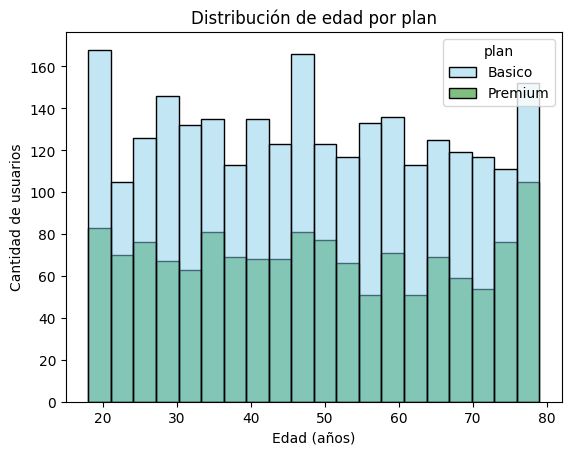

In [ ]:
# Histograma para visualizar la edad (age)
sns.histplot(data=user_profile, x='age', hue='plan', palette=['skyblue', 'green'], bins=20)
plt.title('Distribución de edad por plan')
plt.xlabel('Edad (años)')
plt.ylabel('Cantidad de usuarios')

plt.show()

💡Insights:
- Distribución **aproximadamente uniforme**: hay clientes en proporciones similares en todas las edades, de 18 a 79 años.
- Ambos planes muestran la misma forma, así que **la edad no parece determinar el plan contratado**.
- La barra más alta alrededor de los 48 años se explica por la imputación del sentinel -999 con la mediana.

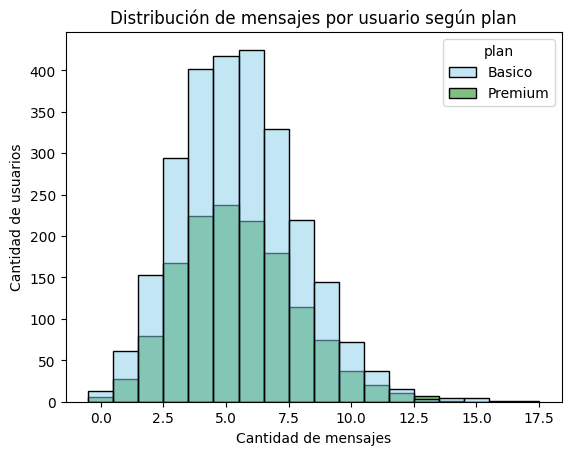

In [ ]:
# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], discrete=True)
plt.title('Distribución de mensajes por usuario según plan')
plt.xlabel('Cantidad de mensajes')
plt.ylabel('Cantidad de usuarios')
plt.show()

💡Insights:

- Distribución **ligeramente sesgada a la derecha**: la mayoría de los usuarios envía entre 4 y 6 mensajes, y pocos superan los 12.
- Los usuarios Básico y Premium tienen el mismo patrón de envío. **Premium no envía más mensajes que Básico**, aunque su plan incluye 5 veces más.

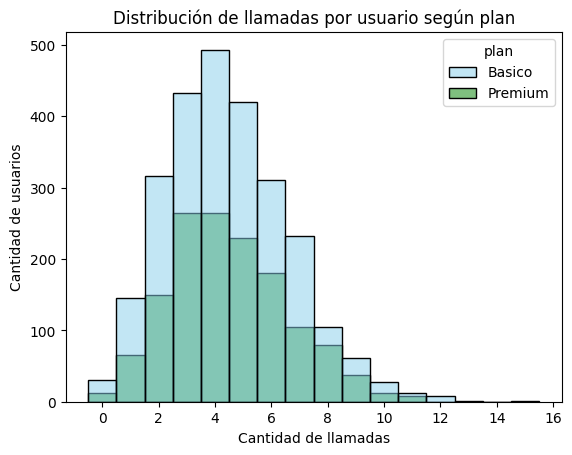

In [ ]:
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], discrete=True)
plt.title('Distribución de llamadas por usuario según plan')
plt.xlabel('Cantidad de llamadas')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights:
- Distribución **ligeramente sesgada a la derecha**, con la mayoría de los usuarios entre 3 y 5 llamadas.
- No existe un patrón diferenciado por plan: **Básico y Premium realizan una cantidad similar de llamadas**.

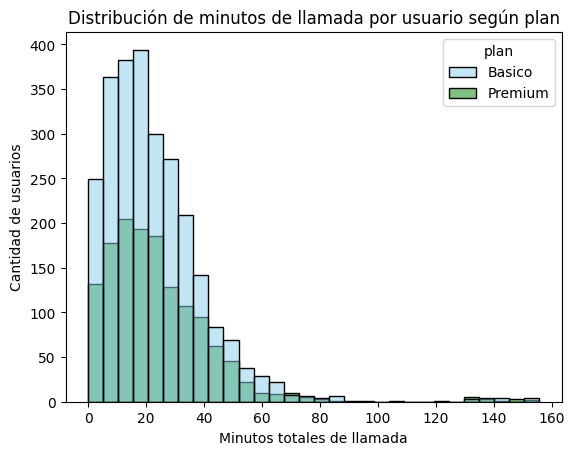

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], bins=30)
plt.title('Distribución de minutos de llamada por usuario según plan')
plt.xlabel('Minutos totales de llamada')
plt.ylabel('Cantidad de usuarios')
plt.show()


💡Insights:
- Distribución **claramente sesgada a la derecha**: la mayoría de los usuarios acumula entre 10 y 25 minutos, con una cola larga hacia valores altos.
- Se observa un **pequeño grupo aislado de usuarios entre 130 y 155 minutos**, separado del resto por un vacío entre ~90 y ~125 minutos. Son posibles outliers (uso intensivo, uso comercial o error de registro) que se analizarán en el paso 5.2.
- El comportamiento es similar en ambos planes: **los usuarios Premium no consumen más minutos que los Básico**.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age`
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

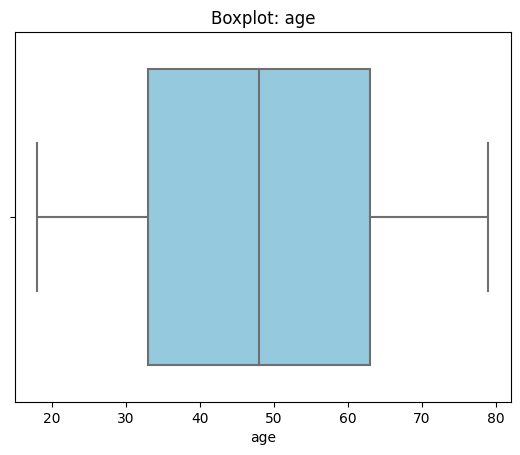

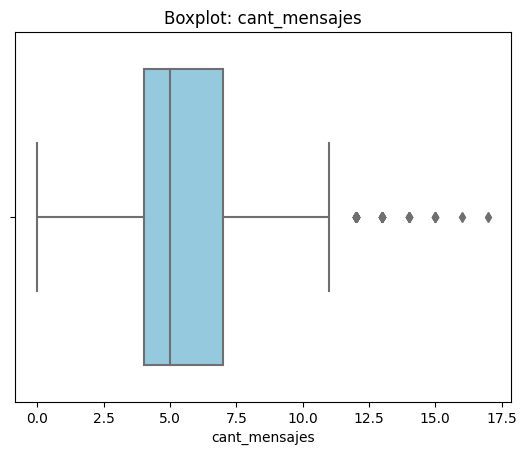

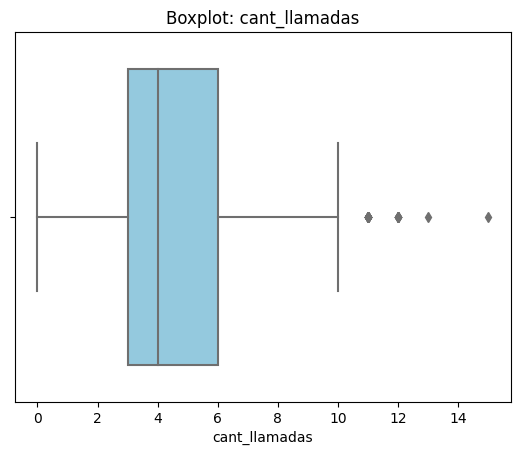

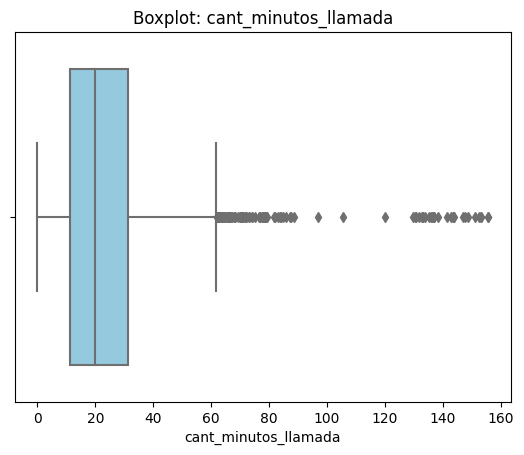

In [ ]:
# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    sns.boxplot(x=user_profile[col], color='skyblue')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights:
- `age`: **no presenta outliers**. Las edades van de 18 a 79 años y quedan dentro de los bigotes, como corresponde a una distribución uniforme.
- `cant_mensajes`: **presenta outliers** solo hacia valores altos (usuarios con más de 11 mensajes).
- `cant_llamadas`: **presenta outliers** solo hacia valores altos (usuarios con más de 10 llamadas).
- `cant_minutos_llamada`: **presenta outliers** solo hacia valores altos, más numerosos y alejados. Destaca un grupo de usuarios entre 130 y 155 minutos.

In [ ]:
# Calcular límites con el método IQR
columnas_limites = ['cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_limites:
    q1 = user_profile[col].quantile(0.25)
    q3 = user_profile[col].quantile(0.75)
    iqr = q3 - q1
    limite_superior = q3 + 1.5 * iqr
    n_outliers = (user_profile[col] > limite_superior).sum()
    print(f"{col}: límite superior = {limite_superior:.2f} | outliers = {n_outliers}")


cant_mensajes: límite superior = 11.50 | outliers = 46
cant_llamadas: límite superior = 10.50 | outliers = 30
cant_minutos_llamada: límite superior = 61.87 | outliers = 109


In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

,cant_mensajes,cant_llamadas,cant_minutos_llamada
count,4000.000000,4000.000000,4000.000000
mean,5.523000,4.477000,23.311225
std,2.359738,2.145139,18.169564
min,0.000000,0.000000,0.000000
25%,4.000000,3.000000,11.107500
50%,5.000000,4.000000,19.780000
75%,7.000000,6.000000,31.412500
max,17.000000,15.000000,155.690000


💡Insights:
- `cant_mensajes`: **se mantienen** los 46 outliers (1,2 %). El máximo (17) supera el límite superior (11,5), pero es un valor posible que representa a usuarios más activos, no un error de registro.
- `cant_llamadas`: **se mantienen** los 30 outliers (0,8 %). El máximo (15) frente al límite (10,5) es un consumo alto pero realista.
- `cant_minutos_llamada`: **se mantienen** los 109 outliers (2,7 %). El máximo (155,7 min) está lejos del límite (61,9), pero es un consumo posible. El grupo aislado entre 130 y 155 minutos merece **revisión adicional**: podría corresponder a uso comercial, fraude o error de registro, y se recomienda auditarlo con el área encargada.
- **Justificación general:** los outliers son pocos, no corresponden a valores imposibles y representan a los clientes de **alto consumo**, un segmento clave para la segmentación y las recomendaciones comerciales. Eliminarlos sesgaría el análisis hacia el usuario promedio.

---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [ ]:
# Crear columna grupo_uso
def clasificar_uso(fila):
    if fila['cant_llamadas'] < 5 and fila['cant_mensajes'] < 5:
        return 'Bajo uso'
    elif fila['cant_llamadas'] < 10 and fila['cant_mensajes'] < 10:
        return 'Uso medio'
    else:
        return 'Alto uso'

user_profile['grupo_uso'] = user_profile.apply(clasificar_uso, axis=1)

In [ ]:
# verificar cambios
print(user_profile['grupo_uso'].value_counts())
user_profile.head()

Uso medio    2943
Bajo uso      779
Alto uso      278
Name: grupo_uso, dtype: int64


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [ ]:
# Crear columna grupo_edad
def clasificar_edad(edad):
    if edad < 30:
        return 'Joven'
    elif edad < 60:
        return 'Adulto'
    else:
        return 'Adulto Mayor'

user_profile['grupo_edad'] = user_profile['age'].apply(clasificar_edad)

In [ ]:
# verificar cambios
print(user_profile['grupo_edad'].value_counts())
user_profile.head()

Adulto          2018
Adulto Mayor    1222
Joven            760
Name: grupo_edad, dtype: int64


,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38.0,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7,3,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53.0,<NA>,2022-01-01 06:34:17.914478619,Basico,NaN,5,10,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57.0,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5,2,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69.0,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11,3,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63.0,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4,3,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

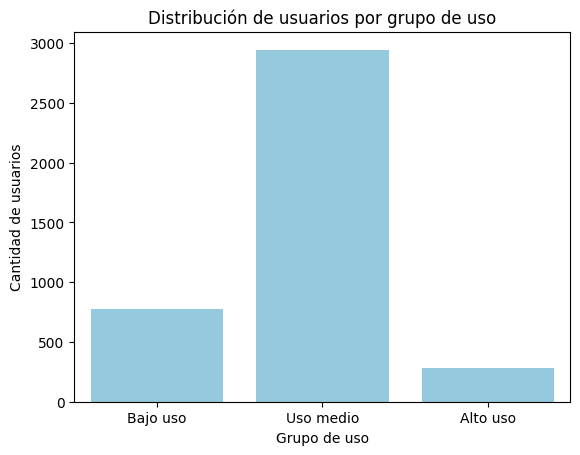

In [ ]:
# Visualización de los segmentos por uso
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], color='skyblue')
plt.title('Distribución de usuarios por grupo de uso')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')

plt.show()

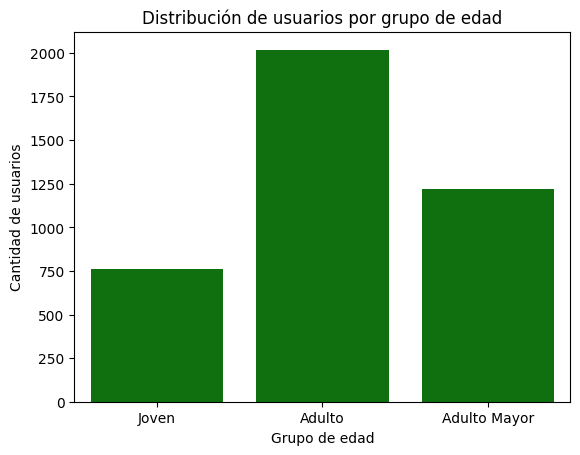

In [ ]:
# Visualización de los segmentos por edad
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], color='green')
plt.title('Distribución de usuarios por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de usuarios')
plt.show()

grupo_uso  Bajo uso  Uso medio  Alto uso
plan                                    
Basico         19.8       73.1       7.1
Premium        18.9       74.4       6.6


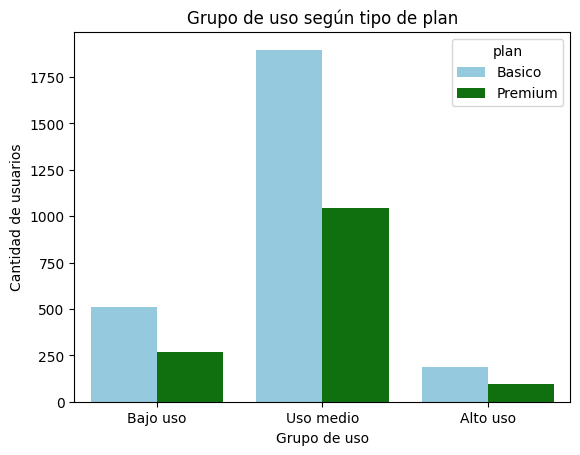

In [ ]:
# Grupo de uso según plan (% dentro de cada plan)
tabla = pd.crosstab(user_profile['plan'], user_profile['grupo_uso'], normalize='index') * 100
print(tabla[['Bajo uso', 'Uso medio', 'Alto uso']].round(1))

sns.countplot(data=user_profile, x='grupo_uso', hue='plan',
              order=['Bajo uso', 'Uso medio', 'Alto uso'], palette=['skyblue', 'green'])
plt.title('Grupo de uso según tipo de plan')
plt.xlabel('Grupo de uso')
plt.ylabel('Cantidad de usuarios')
plt.show()


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:**
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
- `age`: sentinel **-999**, que distorsionaba la media (33,7 frente a una mediana de 47) → reemplazado por la mediana (48).
- `city`: **565 registros sin ciudad (14,1 %)**, 469 nulos y 96 con el sentinel "?" → unificados como nulos, sin imputar.
- `reg_date`: **40 fechas imposibles en 2026 (1 %)** → marcadas como nulas, conservando el resto de la información del cliente.
- `churn_date`: **3.534 nulos (88,4 %)** → se conservan, porque indican clientes activos.
- `duration` (55,2 % nulos) y `length` (44,7 % nulos): **nulos estructurales (MAR)** que dependen del tipo de registro → se mantienen. Se detectaron 28 registros inconsistentes (0,07 %): mensajes con duración y llamadas con longitud.
- `date`: 50 nulos (0,1 %), con impacto mínimo.


🔍 **Segmentos por Edad**
- **Adulto (30–59): 50,5 %**, **Adulto Mayor (60+): 30,6 %** y **Joven (<30): 19,0 %**.
- La edad se distribuye de forma uniforme entre 18 y 79 años, y **no se observan diferencias relevantes de consumo ni de plan contratado entre grupos de edad**.


📊 **Segmentos por Nivel de Uso**
- **Uso medio: 73,6 %**, **Bajo uso: 19,5 %** y **Alto uso: 7,0 %**.
- El cliente típico registra unos **5 mensajes, 4 llamadas y 20 minutos** (medianas), muy por debajo de lo incluido en cualquier plan (Básico: 100 mensajes y 100 min; Premium: 500 mensajes y 600 min).
- **El perfil de uso es casi idéntico entre planes**: el 7,1 % de los clientes Básico y el 6,6 % de los Premium son de alto uso.
- **Outliers:** 46 usuarios en mensajes, 30 en llamadas y 109 en minutos, Se mantuvieron por ser valores posibles. Destaca un grupo aislado entre 130 y 155 minutos que conviene auditar (posible uso comercial, fraude o error de registro).


➡️ Esto sugiere que ...


💡 **Recomendaciones**
- **Crear un plan de entrada más económico** (por ejemplo, 20 mensajes y 50 minutos) para el segmento de bajo uso (19,5 %), que hoy paga por capacidad que no usa y es más propenso a cancelar.
- **Revisar el valor del plan Premium**: incorporar beneficios diferenciales (más GB de datos, roaming, prioridad de servicio) en lugar de minutos y mensajes que no se consumen. De lo contrario, existe riesgo de cambiar de plan cuando el cliente note que no lo aprovecha.
- **Ofrecer planes a la medida o por consumo** al segmento de alto uso (7 %), el más valioso por su nivel de actividad y potencial de fidelización.
- **Auditar los usuarios del grupo 130–155 minutos** para descartar fraude o uso comercial en planes personales.
- **Mejorar la calidad del registro**: validar la edad y la ciudad al momento de captura y bloquear fechas futuras en el sistema.

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`